# Operating modes: comparing classifiers

`operating_mode_dataset(2).ipynb` builds the features and fits one model, a
`HistGradientBoostingClassifier`. This notebook starts from the table it wrote,
`data/labelled.parquet`, and puts several classifiers through exactly the same test:

| step | what happens | why |
|---|---|---|
| 1. Load | one row per labelled vessel-minute, 39 features, the mode as label | feature engineering already happened in the dataset notebook |
| 2. Clean | check for duplicates and infinities, clip values outside the plausible range, fill gaps that have a known meaning | a model can only be as clean as its input |
| 3. Split | whole episodes (port calls, voyages) go to train or to test, never single minutes | neighbouring minutes are near-copies, a row split leaks the answer |
| 4. Ceiling | labeller A against labeller B | no model scored against these labels can be expected to beat the people |
| 5. Models | HGB (baseline), Random Forest, Extra Trees, a single tree, logistic regression, k-nearest neighbours, and an LSTM | from strong to simple, plus one model that reads the minutes in order |
| 6. Test | fit on train, score once on the test episodes no model has seen | the honest number |
| 7. Cross-validation | 5 folds over the training episodes | a second, steadier estimate, and the place to tune |
| 8. Leakage demo | the same model with rows shuffled instead of episodes | shows how much a wrong split inflates the score |
| 9. Compare | per-mode F1 next to the ceiling | overall accuracy hides the hard pair, in port vs cargo operations |
| 10. Importance | what Random Forest relies on | which signals carry the decision |

Run `operating_mode_dataset(2).ipynb` once first so that `data/labelled.parquet` exists.
The LSTM needs PyTorch (`pip install torch` in the notebook's environment); without it the
notebook runs everything else and skips the LSTM. Expect 10 to 30 minutes for a full run;
the LSTM and the cross-validation are the slow parts, `RUN_LSTM = False` skips the LSTM.

In [1]:
from pathlib import Path

ROOT = Path(".")             # package folder with labels.csv and data/
DATA = ROOT / "data"

SPLIT = "time"               # "time": episodes starting on/after CUTOFF are test
                             # "vessel": TEST_VESSEL is test, the other labelled vessel is train
CUTOFF = "2025-07-01"
TEST_VESSEL = "wendover-trader"
GAP_HOURS = 6                # must match the dataset notebook, it defines the episodes

N_FOLDS = 5                  # cross-validation folds over the training episodes
USE_MISSING_FLAGS = True     # let models see *that* a value was missing (see step 2)
RUN_LSTM = True              # step 5b, needs PyTorch; the slowest model by far
RUN_TUNING = False           # step 11, a grouped hyperparameter search for Random Forest (slow)
RANDOM_STATE = 0
N_JOBS = -1                  # CPU cores for the forests and k-NN, -1 = all

In [2]:
import re
import time
from copy import deepcopy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             cohen_kappa_score, confusion_matrix, f1_score, make_scorer)
from sklearn.model_selection import KFold, RandomizedSearchCV, StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

MODES = ["sea_passage", "manoeuvring", "at_anchor", "in_port", "cargo_operations"]
META = ["vessel", "timestamp", "episode", "label_A", "label_B", "mode", "near_boundary", "split"]

# chart styling: recessive axes and grid, one blue ramp for magnitude
INK, INK_2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": INK_2, "axes.grid": False, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
})
from matplotlib.colors import LinearSegmentedColormap
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281"])


def slug(name):
    # 'Wendover Trader' -> 'wendover-trader'
    return re.sub(r"[^a-z0-9]+", "-", str(name).lower()).strip("-")


def macro_f1_present(y_true, y_pred):
    # Macro F1 over the modes that occur in y_true. A fold or test set without an
    # anchorage should not score a 0 for at_anchor just because there was nothing to find.
    return f1_score(y_true, y_pred, labels=sorted(set(y_true)), average="macro", zero_division=0)


SCORER = make_scorer(macro_f1_present)

## 1. Load the prepared table

Each row is one minute of one vessel that a labeller put a mode on. What is already done
by the dataset notebook, so you know what you are starting from:

- **raw → minute grid**: the 15 s samples are averaged to one row per minute; heading and
  wind direction as sine and cosine, never as angles.
- **features**: 39 numbers per minute, scaled by the vessel register so they mean the same
  on a small and a large ship (power as a fraction of installed power, position wander in
  ship lengths, draught as 0 = ballast to 1 = laden), plus rolling windows of 15 to 180 minutes.
- **labels**: each minute gets labeller A's and B's mode; where both labelled it and
  disagree, the minute was dropped. Minutes with no telemetry were dropped too.
- **episode**: which port call or voyage the minute belongs to.
- **near_boundary**: within 5 minutes of a label boundary, where the labels are least trustworthy.

In [3]:
df = pd.read_parquet(DATA / "labelled.parquet")
FEATURES = [c for c in df.columns if c not in META]

print(f"{len(df):,} labelled minutes, {len(FEATURES)} features, "
      f"{df['episode'].nunique()} episodes, vessels {sorted(df['vessel'].unique())}")
display(df.head(3))

hours = (df.pivot_table(index="mode", columns="vessel", values="timestamp", aggfunc="size")
         .reindex(MODES) / 60).round(1)
hours["total"] = hours.sum(axis=1)
hours   # labelled hours per mode

162,470 labelled minutes, 39 features, 23 episodes, vessels ['brayton-trader', 'wendover-trader']


,vessel,timestamp,episode,label_A,label_B,mode,near_boundary,split,sog_kn,stw_frac,stw_minus_sog_kn,sog_mean_15,sog_std_15,sog_mean_60,sog_std_60,stw_minus_sog_mean_60,power_frac,rpm_frac,fuel_frac,power_frac_mean_15,power_frac_std_15,power_frac_mean_60,power_frac_std_60,rudder_abs_deg,rudder_abs_mean_15,rudder_std_15,rudder_abs_mean_60,rudder_std_60,turn_rate_mean_15,turn_rate_mean_60,heading_circstd_60,heading_circstd_180,pos_spread_60_shiplengths,pos_spread_180_shiplengths,load_frac,load_rate_abs_60,load_rate_abs_180,trim_std_60,trim_std_180,heel_std_60,heel_std_180,heel_abs_deg,wind_rel_kn,wind_rel_cos,wind_rel_cos_mean_60,hours_since_moving,hours_until_moving
0,brayton-trader,2024-09-01 00:00:00,brayton-trader-01,manoeuvring,manoeuvring,manoeuvring,True,train,5.7000,0.440116,-0.0225,5.344062,0.238717,4.265333,0.862988,-0.023333,0.059491,0.400149,0.060263,0.056601,0.002045,0.047973,0.006906,8.775,7.478125,5.297918,5.851666,5.210812,3.582150,NaN,46.126884,46.999798,1.577472,3.611563,0.002500,NaN,NaN,0.029313,0.025763,0.291598,0.322367,0.8125,NaN,NaN,NaN,0.0,0.0
1,brayton-trader,2024-09-01 00:01:00,brayton-trader-01,manoeuvring,manoeuvring,manoeuvring,True,train,5.5475,0.431783,0.0225,5.288611,0.278453,4.212742,0.897588,-0.021694,0.058953,0.396726,0.059396,0.056222,0.002226,0.047573,0.007146,1.025,6.850000,5.801158,5.665322,5.192453,3.456256,4.442513,46.852642,46.892029,1.629195,3.611163,0.002917,NaN,NaN,0.029166,0.025644,0.303364,0.320584,0.4025,NaN,NaN,NaN,0.0,0.0
2,brayton-trader,2024-09-01 00:02:00,brayton-trader-01,manoeuvring,manoeuvring,manoeuvring,True,train,5.4800,0.424031,-0.0100,5.238500,0.306647,4.162422,0.927741,-0.021094,0.057476,0.385685,0.057891,0.055844,0.002415,0.047169,0.007393,5.775,6.957500,5.495999,5.772656,5.168824,3.413890,4.447589,47.637230,46.780033,1.680814,3.610364,0.002500,NaN,NaN,0.028737,0.025517,0.309515,0.318896,0.1775,NaN,NaN,NaN,0.0,0.0


vessel,brayton-trader,wendover-trader,total
mode,,,
sea_passage,790.4,731.6,1522.0
manoeuvring,34.2,40.2,74.4
at_anchor,58.2,40.2,98.4
in_port,118.3,77.3,195.6
cargo_operations,394.8,422.6,817.4


Sea passage has about 25 times the hours of manoeuvring. A model that says "sea passage"
every minute is already about half right, so accuracy alone says little. Everything below is
scored **per mode** with F1, and summarised as **macro F1**, the plain average over modes,
where manoeuvring counts as much as sea passage.

## 2. Clean

### 2a. Basic checks

In [4]:
checks = pd.Series({
    "duplicate (vessel, timestamp) rows": df.duplicated(["vessel", "timestamp"]).sum(),
    "infinite feature values": np.isinf(df[FEATURES].to_numpy()).sum(),
    "constant feature columns": (df[FEATURES].nunique() <= 1).sum(),
    "rows with an unknown mode": (~df["mode"].isin(MODES)).sum(),
    "rows with any missing feature": df[FEATURES].isna().any(axis=1).sum(),
}, name="count")
checks.to_frame()

,count
"duplicate (vessel, timestamp) rows",0
infinite feature values,0
constant feature columns,0
rows with an unknown mode,0
rows with any missing feature,4108


### 2b. Missing values: where and why

Missing values are not all the same. Before filling anything, look at **which mode** they
fall in.

In [5]:
na = df[FEATURES].isna()
missing = pd.DataFrame({"missing_rows": na.sum(), "missing_%": 100 * na.mean()})
missing = missing[missing["missing_rows"] > 0].sort_values("missing_rows", ascending=False)
display(missing.round(2))

print("% of each mode's minutes where the value is missing:")
display((na[missing.index].groupby(df["mode"]).mean() * 100).reindex(MODES).round(1))

,missing_rows,missing_%
wind_rel_kn,3057,1.88
wind_rel_cos,3057,1.88
wind_rel_cos_mean_60,3029,1.86
hours_since_moving,1066,0.66
load_rate_abs_180,180,0.11
load_rate_abs_60,60,0.04
turn_rate_mean_60,2,0.00


% of each mode's minutes where the value is missing:


,wind_rel_kn,wind_rel_cos,wind_rel_cos_mean_60,hours_since_moving,load_rate_abs_180,load_rate_abs_60,turn_rate_mean_60
mode,,,,,,,
sea_passage,0.0,0.0,0.0,0.0,0.0,0.0,0.0
manoeuvring,58.7,58.7,58.5,0.0,2.0,0.7,0.0
at_anchor,1.7,1.7,1.6,18.1,1.5,0.5,0.0
in_port,2.6,2.6,2.5,0.0,0.0,0.0,0.0
cargo_operations,0.1,0.1,0.1,0.0,0.0,0.0,0.0


Three different stories:

- **Wind** is missing in about 60 % of manoeuvring minutes and almost nowhere else, on both
  vessels and in both periods. The anemometer drops out at harbour speeds. That makes "wind
  missing" a real manoeuvring signal in this data. Whether the supplier-Y ships (Calder
  Trader, Harrowgate) behave the same is unknown, so `USE_MISSING_FLAGS` lets you train with
  and without it and compare.
- **hours_since_moving** is missing only at the start of the data (Wendover Trader at anchor
  on 1 September 2024): the ship has not moved for as long as we can see. That is not
  "unknown", it means "a long time", so it is filled with the 72 h cap the feature already uses.
- **load_rate** and **turn_rate** windows are missing for a few rows at the edge of a loaded
  block. Harmless, the imputer fills them.

### 2c. Values outside the plausible range

`parameters.html` gives a plausible range per column. Relative wind tops out at 70 kn there,
yet a few minutes read up to 100 kn: sensor spikes. Speed over ground dips a hair below
zero: GPS noise. Both are clipped to the range.

These steps use fixed rules, nothing learned from the data, so applying them to the whole
table before the split leaks nothing. The median used for the remaining gaps **is** learned,
so that step lives inside each model's pipeline (step 5) and is fitted on training rows only.

In [6]:
PLAUSIBLE = {"wind_rel_kn": (0, 70), "sog_kn": (0, None)}    # from parameters.html
HOURS_CAP = 72                                               # the clip the dataset notebook uses


def clean_features(X):
    # Rule-based cleaning, the same for every row and every model. Apply it to any new
    # data before predicting, too.
    X = X.copy()
    for col, (lo, hi) in PLAUSIBLE.items():
        X[col] = X[col].clip(lo, hi)
    for col in ("hours_since_moving", "hours_until_moving"):
        X[col] = X[col].fillna(HOURS_CAP)       # never seen moving = at least the cap
    return X


before = df[FEATURES]
after = clean_features(before)
changed = (before.ne(after) & before.notna()).sum() + (before.isna() & after.notna()).sum()
print("values changed per column:")
display(changed[changed > 0].rename("changed").to_frame())
df[FEATURES] = after
print(f"rows still missing a value: {df[FEATURES].isna().any(axis=1).sum():,} "
      "(filled inside the pipelines)")

values changed per column:


,changed
sog_kn,3
wind_rel_kn,210
hours_since_moving,1066


rows still missing a value: 3,147 (filled inside the pipelines)


## 3. Split by episode

Two minutes next to each other are nearly identical. If one goes to training and the other
to test, the model is tested on something it has effectively already seen. So the unit of
the split is the **episode**: a whole port call or voyage goes to one side.

- `SPLIT = "time"`: episodes that start on or after `CUTOFF` are test. Closest to real use:
  train on the past, predict the future.
- `SPLIT = "vessel"`: one labelled vessel is train, the other test. Both are the same class A
  design with identical register entries, so this checks ship-to-ship variation, not a
  different design. The real transfer test is Calder Trader and Harrowgate, which have no labels.

Training leaves out the rows near a label boundary; test keeps every row, so its score is not
flattered. Two training tables come out of this:

- `train_all`: every minute of the training episodes. The LSTM reads these in order, so it
  needs the boundary minutes as context, but it does not learn from their labels.
- `train`: the same without the boundary minutes. The row models learn from these, and
  cross-validation scores on these.

In [7]:
def load_labels(path, gap_hours=6):
    # labels.csv -> stretches with labeller and episode, as in the dataset notebook.
    lab = pd.read_csv(path, parse_dates=["start", "end"])
    lab[["start", "end"]] = lab[["start", "end"]].astype("datetime64[ns]")
    lab["vessel"] = lab["vessel"].map(slug)
    lab["labeller"] = lab["labelled_by"].astype(str).str.split().str[-1]
    lab = lab.sort_values(["vessel", "start"]).reset_index(drop=True)
    reach = lab.groupby("vessel")["end"].transform(lambda s: s.cummax().shift())
    new = reach.isna() | (lab["start"] > reach + pd.Timedelta(hours=gap_hours))
    n = new.astype(int).groupby(lab["vessel"]).cumsum()
    lab["episode"] = lab["vessel"] + "-" + n.astype(str).str.zfill(2)
    return lab


lab = load_labels(ROOT / "labels.csv", GAP_HOURS)
assert set(df["episode"]) <= set(lab["episode"]), "episodes differ from the dataset notebook, check GAP_HOURS"

if SPLIT == "time":
    ep_start = lab.groupby("episode")["start"].min()
    is_test = df["episode"].isin(ep_start.index[ep_start >= pd.Timestamp(CUTOFF)])
elif SPLIT == "vessel":
    is_test = df["vessel"] == slug(TEST_VESSEL)
else:
    raise ValueError(f"SPLIT must be 'time' or 'vessel', not {SPLIT!r}")

train_all = df[~is_test].reset_index(drop=True)                     # context for the LSTM
train = train_all[~train_all["near_boundary"]].reset_index(drop=True)  # what row models learn from
test = df[is_test].reset_index(drop=True)
assert not set(train_all["episode"]) & set(test["episode"]), "an episode is on both sides"

X_train, y_train, groups = train[FEATURES], train["mode"], train["episode"]
X_test, y_test = test[FEATURES], test["mode"]

print(f"train: {len(train):,} rows from {train['episode'].nunique()} episodes")
print(f"test:  {len(test):,} rows from {test['episode'].nunique()} episodes")


def side(part):
    return pd.DataFrame({"hours": part["mode"].value_counts() / 60,
                         "episodes": part.groupby("mode")["episode"].nunique()})


pd.concat({"train": side(train), "test": side(test)}, axis=1).reindex(MODES).fillna(0).round(1)

train: 90,862 rows from 13 episodes
test:  70,565 rows from 10 episodes


train            test         
                  hours episodes  hours episodes
mode                                            
sea_passage       811.2       13  707.1       10
manoeuvring        39.6       10   28.3        6
at_anchor          76.7        4   21.0        2
in_port           138.7       10   53.2        6
cargo_operations  448.2       10  366.5        6

Look at the `episodes` column before trusting any at_anchor score: there are only a handful
of anchorages on each side. A score built on two anchorages can swing a lot with one odd one.

In [8]:
# Same rows as the saved tables? (only expected with the default settings)
if SPLIT == "time" and (DATA / "train.parquet").exists():
    saved = (len(pd.read_parquet(DATA / "train.parquet", columns=["episode"])),
             len(pd.read_parquet(DATA / "test.parquet", columns=["episode"])))
    print("matches data/train.parquet and data/test.parquet" if saved == (len(train), len(test))
          else f"differs from the saved tables {saved}: did the dataset notebook use other settings?")

matches data/train.parquet and data/test.parquet


## 4. The ceiling: labeller A against labeller B

On the minutes both labelled. Computed from `labels.csv`, because the table above has
already dropped the minutes where they disagree.

In [9]:
def minute_labels(lab, who):
    parts = [pd.DataFrame({"vessel": r.vessel, "mode": r.mode,
                           "timestamp": pd.date_range(r.start, r.end, freq="min", inclusive="left")})
             for r in lab[lab["labeller"] == who].itertuples()]
    return pd.concat(parts, ignore_index=True)


both = minute_labels(lab, "A").merge(minute_labels(lab, "B"), on=["vessel", "timestamp"],
                                     suffixes=("_A", "_B"))
a, b = both["mode_A"], both["mode_B"]
print(f"{len(both) / 60:.0f} h labelled by both: accuracy {np.mean(a == b):.3f}, "
      f"kappa {cohen_kappa_score(a, b):.3f}, macro F1 {f1_score(a, b, labels=MODES, average='macro'):.3f}")
rater_f1 = pd.Series(f1_score(a, b, labels=MODES, average=None), index=MODES, name="rater agreement")
rater_f1.round(3).to_frame()

774 h labelled by both: accuracy 0.914, kappa 0.870, macro F1 0.826


,rater agreement
sea_passage,0.999
manoeuvring,0.944
at_anchor,0.557
in_port,0.692
cargo_operations,0.940


The two people mostly disagree about **at_anchor vs in_port** and **in_port vs
cargo_operations**. Keep in mind that the test episodes (after July 2025) were labelled by
labeller A alone. A model trained mostly on A's labels can score above the A-vs-B agreement,
because it has learned A's habits, not because it is better than a person.

## 5. The models

Every model except HGB is a pipeline, so the same steps happen at training and at
prediction time, and anything learned (medians, scales) is learned from training rows only:

- `SimpleImputer(median, add_indicator=USE_MISSING_FLAGS)` fills the remaining gaps and, with
  the flag on, adds a 0/1 column per gappy feature saying "this was missing".
- `StandardScaler` for the models that measure distances or weigh features linearly
  (logistic regression, k-NN). Trees split on thresholds and do not need it.
- `class_weight="balanced"` gives each mode the same total weight, so 28 hours of
  manoeuvring are not drowned out by 700 hours of sea passage. k-NN has no class weights.

| model | idea | strengths here | weaknesses here |
|---|---|---|---|
| HistGradientBoosting | trees built one after another, each fixing the last one's errors | strong, fast, handles missing values itself | more knobs, can overfit with many iterations |
| Random Forest | 300 deep trees on bootstrap samples, majority vote | robust, few settings matter, hard to overfit badly | large to store, slower to predict |
| Extra Trees | like a forest, but split thresholds are drawn at random | faster than RF, smoother boundaries | slightly less sharp on small classes |
| Decision tree (depth 8) | one tree | readable, a floor for the ensembles | unstable, coarse |
| Logistic regression | one linear score per mode | a baseline, shows how much is linear | modes are not linearly separable in these features |
| k-NN (k = 25) | vote of the 25 most similar training minutes | no training | slow to predict, sensitive to feature scaling, no class weights |
| LSTM (step 5b) | a recurrent network reading 4-hour stretches of minutes in order | learns what comes before and after a minute | slowest, needs PyTorch, more settings, only 13 training episodes to learn from |

Do not use a forest's out-of-bag score here: its "unseen" rows are neighbours of the training
rows, the same leak a row split has.

In [11]:
def prep(scale):
    steps = [SimpleImputer(strategy="median", add_indicator=USE_MISSING_FLAGS)]
    return steps + [StandardScaler()] if scale else steps


hgb = HistGradientBoostingClassifier(class_weight="balanced", early_stopping=False,
                                     max_iter=200, learning_rate=0.1, random_state=RANDOM_STATE)

ESTIMATORS = {
    # HGB handles NaN itself; without missing flags it gets the plain median fill like the rest
    "hist_gradient_boosting": hgb if USE_MISSING_FLAGS else make_pipeline(*prep(False), hgb),
    "random_forest": make_pipeline(*prep(False), RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3, max_features="sqrt", class_weight="balanced_subsample",
        n_jobs=N_JOBS, random_state=RANDOM_STATE)),
    "extra_trees": make_pipeline(*prep(False), ExtraTreesClassifier(
        n_estimators=300, min_samples_leaf=3, max_features="sqrt", class_weight="balanced_subsample",
        n_jobs=N_JOBS, random_state=RANDOM_STATE)),
    "decision_tree": make_pipeline(*prep(False), DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE)),
    "logistic_regression": make_pipeline(*prep(True), LogisticRegression(
        C=1.0, max_iter=3000, class_weight="balanced")),
    "k_nearest_neighbours": make_pipeline(*prep(True), KNeighborsClassifier(
        n_neighbors=25, weights="distance", n_jobs=N_JOBS)),
}


class RowModel:
    # Gives a scikit-learn model the same interface as the LSTM below: fit and predict take a
    # table with the meta columns. Each minute is classified on its own features; the
    # near-boundary minutes are left out of training, as in the dataset notebook.
    def __init__(self, estimator):
        self.estimator = estimator

    def fit(self, part):
        rows = part[~part["near_boundary"]] if "near_boundary" in part else part
        self.model_ = clone(self.estimator).fit(rows[FEATURES], rows["mode"])
        self.classes_ = self.model_.classes_
        return self

    def predict(self, part):
        return self.model_.predict(part[FEATURES])

    def predict_proba(self, part):
        return self.model_.predict_proba(part[FEATURES])


MODELS = {name: RowModel(est) for name, est in ESTIMATORS.items()}

### 5b. The LSTM: reading the minutes in order

Every model above looks at one minute at a time. Its only sense of before and after comes
from the rolling-window features. An LSTM (long short-term memory network) reads a vessel's
minutes **in order** and carries a memory along, so it can learn sequences: approach, then
alongside, then cargo, then idle, then departure.

How it is set up here, and why:

- **Many-to-many.** The input is a 4-hour window (`seq_len = 240` minutes) of the same 39
  cleaned features; the output is a mode for every minute in the window. One window gives
  240 training examples, so 13 training episodes are enough to train on.
- **Bidirectional.** It reads the window forwards and backwards. Like the centred features,
  that suits labelling history offline; a real-time classifier would read forwards only.
- **Same preparation as the others.** Median fill and missing flags, then scaling, both fitted
  on training minutes only. Neural networks need scaled inputs.
- **Boundary minutes are input, not targets.** The LSTM sees them, so the sequence is not
  cut at every mode change, but their labels carry no weight in the loss.
- **Class weights.** Each mode gets the same total weight in the loss, like
  `class_weight="balanced"` above.
- **Sequences break at gaps.** Different vessel, or more than `max_gap_min` minutes
  missing (an unlabelled stretch, dropped disagreements): a new sequence starts.
- **Prediction.** Windows overlap by half; each minute's class probabilities are averaged
  over the windows that contain it, so no minute sits only at the edge of a window.
- **A fixed number of epochs, no early stopping on the test set.** Stopping when test loss
  is lowest would quietly tune on test. To pick `epochs`, compare a few values in
  cross-validation.

The settings below came from trying a few on two of the cross-validation folds, never on
test: a two-layer, 64-unit network was three times slower and worse on the fold with an
anchorage, and the score barely moved between 4 and 20 epochs.

It needs PyTorch. If `import torch` fails, the LSTM is skipped and everything else runs.

In [13]:
try:
    import torch
    from torch import nn
    from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
    HAVE_TORCH = True
except ImportError:
    HAVE_TORCH = False

LSTM_SETTINGS = dict(
    seq_len=240,        # minutes per training window (4 h)
    hidden=48,          # memory size per direction
    layers=1,
    dropout=0.2,
    epochs=12,
    batch_size=32,
    lr=2e-3,
    max_gap_min=5,      # a longer hole in the minutes starts a new sequence
)
DEVICE = "mps"          # "cuda" on an NVIDIA GPU; "mps" on Apple silicon can be faster or slower, try it

In [16]:
if HAVE_TORCH:
    class BiLSTMNet(nn.Module):
        def __init__(self, n_in, n_out, hidden, layers, dropout):
            super().__init__()
            self.lstm = nn.LSTM(n_in, hidden, num_layers=layers, batch_first=True, bidirectional=True,
                                dropout=dropout if layers > 1 else 0.0)
            self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * hidden, n_out))

        def forward(self, x, lengths):
            # packing makes the backward direction start at each sequence's real end, not in the padding
            packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
            out, _ = self.lstm(packed)
            out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.shape[1])
            return self.head(out)                 # (batch, time, mode) scores


class LSTMClassifier:
    # Bidirectional LSTM over each vessel's minutes, one mode per minute.
    # fit(part) and predict(part) take a table with vessel, timestamp, near_boundary, mode and FEATURES.

    def __init__(self, seq_len=240, hidden=48, layers=1, dropout=0.2, epochs=12, batch_size=32, lr=2e-3,
                 max_gap_min=5, missing_flags=True, device="cpu", random_state=0, verbose=False):
        self.seq_len, self.hidden, self.layers, self.dropout = seq_len, hidden, layers, dropout
        self.epochs, self.batch_size, self.lr, self.max_gap_min = epochs, batch_size, lr, max_gap_min
        self.missing_flags, self.device, self.random_state, self.verbose = missing_flags, device, random_state, verbose

    # -- sequences
    def _segments(self, p):
        # Row positions of runs of consecutive minutes of one vessel, in time order.
        order = p.sort_values(["vessel", "timestamp"]).index.to_numpy()
        v, t = p["vessel"].to_numpy()[order], p["timestamp"].to_numpy()[order]
        new = np.r_[True, (v[1:] != v[:-1]) | (np.diff(t) > np.timedelta64(self.max_gap_min, "m"))]
        starts = np.flatnonzero(new)
        return [order[s:e] for s, e in zip(starts, np.r_[starts[1:], len(order)])]

    def _windows(self, segs, stride):
        # (segment, start, end) of windows of seq_len minutes; a shorter segment is one window.
        wins = []
        for k, s in enumerate(segs):
            n = len(s)
            if n <= self.seq_len:
                wins.append((k, 0, n))
                continue
            starts = list(range(0, n - self.seq_len + 1, stride))
            if starts[-1] != n - self.seq_len:
                starts.append(n - self.seq_len)       # last window flush with the end
            wins += [(k, a, a + self.seq_len) for a in starts]
        return wins

    def _batch(self, wins, segs, X, y=None, w=None):
        L = max(e - a for _, a, e in wins)
        xb = np.zeros((len(wins), L, X.shape[1]), np.float32)
        yb = np.zeros((len(wins), L), np.int64)
        wb = np.zeros((len(wins), L), np.float32)       # 0 for padding and for boundary minutes
        for i, (k, a, e) in enumerate(wins):
            idx = segs[k][a:e]
            xb[i, :e - a] = X[idx]
            if y is not None:
                yb[i, :e - a], wb[i, :e - a] = y[idx], w[idx]
        lengths = torch.tensor([e - a for _, a, e in wins])
        to = lambda a: torch.from_numpy(a).to(self.device)
        return to(xb), to(yb), to(wb), lengths

    # -- scikit-learn style interface
    def fit(self, part):
        torch.manual_seed(self.random_state)
        rng = np.random.default_rng(self.random_state)
        p = part.reset_index(drop=True)
        trusted = ~p["near_boundary"].to_numpy(dtype=bool)
        self.classes_ = np.array(MODES, dtype=object)

        self.prep_ = make_pipeline(SimpleImputer(strategy="median", add_indicator=self.missing_flags),
                                   StandardScaler()).fit(p.loc[trusted, FEATURES])
        X = self.prep_.transform(p[FEATURES]).astype(np.float32)
        y = p["mode"].map({m: i for i, m in enumerate(MODES)}).to_numpy(dtype=np.int64)
        counts = np.bincount(y[trusted], minlength=len(MODES))
        class_w = np.where(counts > 0, counts.sum() / (len(MODES) * np.maximum(counts, 1)), 0.0)
        w = (class_w[y] * trusted).astype(np.float32)          # per-minute loss weight

        segs = self._segments(p)
        wins = self._windows(segs, stride=max(1, self.seq_len // 2))
        net = BiLSTMNet(X.shape[1], len(MODES), self.hidden, self.layers, self.dropout).to(self.device)
        opt = torch.optim.Adam(net.parameters(), lr=self.lr)
        self.history_ = []
        for epoch in range(self.epochs):
            net.train()
            order = rng.permutation(len(wins))
            total = weight = 0.0
            for b in range(0, len(order), self.batch_size):
                xb, yb, wb, lengths = self._batch([wins[i] for i in order[b:b + self.batch_size]], segs, X, y, w)
                ce = nn.functional.cross_entropy(net(xb, lengths).reshape(-1, len(MODES)), yb.reshape(-1),
                                                 reduction="none")
                loss = (ce * wb.reshape(-1)).sum() / wb.sum().clamp(min=1e-8)
                opt.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(net.parameters(), 1.0)
                opt.step()
                total += loss.item() * wb.sum().item()
                weight += wb.sum().item()
            self.history_.append(total / weight)
            if self.verbose:
                print(f"    epoch {epoch + 1:>2}/{self.epochs}   training loss {total / weight:.4f}")
        self.net_ = net.eval()
        return self

    def predict_proba(self, part):
        p = part.reset_index(drop=True)
        X = self.prep_.transform(p[FEATURES]).astype(np.float32)
        segs = self._segments(p)
        wins = self._windows(segs, stride=max(1, self.seq_len // 2))
        prob, seen = np.zeros((len(p), len(MODES))), np.zeros(len(p))
        with torch.no_grad():
            for b in range(0, len(wins), 128):
                batch = wins[b:b + 128]
                xb, _, _, lengths = self._batch(batch, segs, X)
                pr = torch.softmax(self.net_(xb, lengths), dim=-1).cpu().numpy()
                for i, (k, a, e) in enumerate(batch):
                    prob[segs[k][a:e]] += pr[i, :e - a]
                    seen[segs[k][a:e]] += 1
        return prob / seen[:, None]          # averaged over the overlapping windows

    def predict(self, part):
        return self.classes_[self.predict_proba(part).argmax(axis=1)]


if RUN_LSTM and HAVE_TORCH:
    MODELS["lstm"] = LSTMClassifier(**LSTM_SETTINGS, missing_flags=USE_MISSING_FLAGS, device=DEVICE,
                                    random_state=RANDOM_STATE)
elif RUN_LSTM:
    print("PyTorch is not installed, so the LSTM is skipped. In a notebook cell:  %pip install torch")
list(MODELS)

['hist_gradient_boosting',
 'random_forest',
 'extra_trees',
 'decision_tree',
 'logistic_regression',
 'k_nearest_neighbours',
 'lstm']

In [13]:
%pip install torch

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.3/127.3 MB 44.4 MB/s  0:00:02 eta 0:00:010:00:01
Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 34.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.3/876.3 kB 26.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 33.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 17.4 MB/s  0:00:00
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [torch]8;5;237m━━━━ 8/9 [torch]ools]

[notice] A new release of pip is available: 26.2 -> 26.2.2
[notice] To update, run: /Users/bekirgulestan/.venv/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 6. Train on the training episodes, test on the unseen ones

Each model is fitted once on train and scored once on test. Do not go back and change
settings because of what you see here; that turns the test set into a tuning set and the
score stops being honest. Tune with cross-validation (step 7 and 11) instead.

`macro_f1_clean` is the same score without the test rows next to a label boundary, to see how
much of the error is just where exactly a mode starts.

In [17]:
def summary_scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "macro_f1": macro_f1_present(y_true, y_pred),
            "kappa": cohen_kappa_score(y_true, y_pred)}


fitted, test_pred, rows = {}, {}, []
away = ~test["near_boundary"].to_numpy()
for name, model in MODELS.items():
    t0 = time.perf_counter()
    model = deepcopy(model).fit(train_all)       # row models drop the boundary minutes themselves
    t1 = time.perf_counter()
    pred = model.predict(test)
    t2 = time.perf_counter()
    fitted[name], test_pred[name] = model, pred
    rows.append({"model": name, **summary_scores(y_test, pred),
                 "macro_f1_clean": macro_f1_present(y_test[away], pred[away]),
                 "fit_s": t1 - t0, "predict_s": t2 - t1})
    print(f"{name:<24} macro F1 {rows[-1]['macro_f1']:.3f}   fit {t1 - t0:6.1f} s   predict {t2 - t1:5.1f} s")

test_scores = pd.DataFrame(rows).set_index("model").sort_values("macro_f1", ascending=False)
test_scores.round(3)

hist_gradient_boosting   macro F1 0.937   fit   10.2 s   predict   0.3 s
random_forest            macro F1 0.956   fit    4.7 s   predict   0.2 s
extra_trees              macro F1 0.954   fit    1.2 s   predict   0.2 s
decision_tree            macro F1 0.863   fit    1.4 s   predict   0.0 s
logistic_regression      macro F1 0.933   fit    1.0 s   predict   0.0 s
k_nearest_neighbours     macro F1 0.944   fit    0.3 s   predict   2.7 s
lstm                     macro F1 0.927   fit   41.9 s   predict   0.6 s


,accuracy,balanced_accuracy,macro_f1,kappa,macro_f1_clean,fit_s,predict_s
model,,,,,,,
random_forest,0.983,0.976,0.956,0.969,0.961,4.706,0.188
extra_trees,0.982,0.972,0.954,0.968,0.958,1.185,0.201
k_nearest_neighbours,0.978,0.962,0.944,0.959,0.949,0.314,2.722
hist_gradient_boosting,0.980,0.929,0.937,0.963,0.944,10.221,0.296
logistic_regression,0.977,0.948,0.933,0.957,0.939,1.045,0.014
lstm,0.966,0.968,0.927,0.937,0.930,41.851,0.554
decision_tree,0.958,0.953,0.863,0.925,0.868,1.400,0.012


### Per mode, next to the ceiling

In [18]:
test_f1 = pd.DataFrame({name: f1_score(y_test, p, labels=MODES, average=None, zero_division=0)
                        for name, p in test_pred.items()}, index=MODES).T.loc[test_scores.index]
test_f1.loc["rater agreement (ceiling)"] = rater_f1
test_f1.loc["test hours"] = [np.sum(y_test == m) / 60 for m in MODES]
display(test_f1.round(3))
test_f1 = test_f1.drop(index="test hours")

,sea_passage,manoeuvring,at_anchor,in_port,cargo_operations
model,,,,,
random_forest,0.999,0.958,0.997,0.849,0.975
extra_trees,0.999,0.956,0.994,0.844,0.975
k_nearest_neighbours,0.999,0.954,0.994,0.806,0.968
hist_gradient_boosting,0.999,0.953,0.979,0.784,0.973
logistic_regression,0.998,0.953,0.948,0.797,0.968
lstm,0.999,0.963,0.995,0.733,0.945
decision_tree,0.982,0.938,0.608,0.817,0.971
rater agreement (ceiling),0.999,0.944,0.557,0.692,0.940
test hours,707.083,28.333,21.000,53.167,366.500


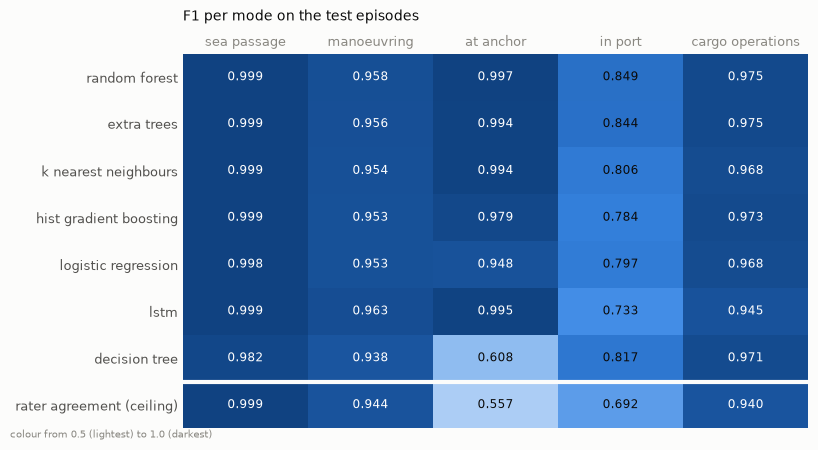

In [19]:
def f1_heatmap(table, title):
    t = table[MODES]
    fig, ax = plt.subplots(figsize=(8.2, 0.42 * len(t) + 1.1))
    ax.imshow(t.to_numpy(dtype=float), cmap=BLUES, vmin=0.5, vmax=1.0, aspect="auto")
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            v = t.iat[i, j]
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8.5,
                    color="#ffffff" if v >= 0.85 else INK)
    ax.set_xticks(range(len(MODES)), [m.replace("_", " ") for m in MODES])
    ax.set_yticks(range(len(t)), [n.replace("_", " ") for n in t.index])
    ax.tick_params(length=0)
    ax.xaxis.tick_top()
    for s in ax.spines.values():
        s.set_visible(False)
    ax.axhline(len(t) - 1.5, color="#fcfcfb", linewidth=3)     # separate the ceiling row
    ax.set_title(title, loc="left", fontsize=10, pad=24)
    fig.text(0.01, 0.01, "colour from 0.5 (lightest) to 1.0 (darkest)", fontsize=7.5, color=MUTED)
    plt.tight_layout()
    plt.show()


f1_heatmap(test_f1, "F1 per mode on the test episodes")

### Where the best models go wrong

Rows are the true mode, columns the prediction, counts are minutes. Change `SHOW` to look at
any other model.

                  precision    recall  f1-score   support

     sea_passage      0.999     0.999     0.999     42425
     manoeuvring      0.971     0.946     0.958      1700
       at_anchor      0.995     0.998     0.997      1260
         in_port      0.749     0.980     0.849      3190
cargo_operations      0.997     0.954     0.975     21990

        accuracy                          0.983     70565
       macro avg      0.942     0.976     0.956     70565
    weighted avg      0.986     0.983     0.984     70565



predicted,sea_passage,manoeuvring,at_anchor,in_port,cargo_operations
true,,,,,
sea_passage,42384,36,5,0,0
manoeuvring,44,1608,0,48,0
at_anchor,2,0,1258,0,0
in_port,0,7,0,3127,56
cargo_operations,0,5,1,999,20985


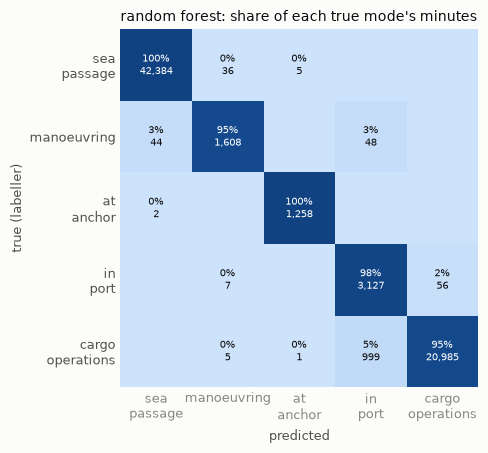

In [22]:
SHOW = "random_forest"

pred = test_pred[SHOW]
print(classification_report(y_test, pred, labels=MODES, digits=3, zero_division=0))
cm = pd.DataFrame(confusion_matrix(y_test, pred, labels=MODES),
                  index=pd.Index(MODES, name="true"), columns=pd.Index(MODES, name="predicted"))
display(cm)

share = cm.div(cm.sum(axis=1), axis=0)      # each row sums to 1: where a true mode's minutes went
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.imshow(share.to_numpy(), cmap=BLUES, vmin=0, vmax=1)
for i in range(len(MODES)):
    for j in range(len(MODES)):
        v, n = share.iat[i, j], cm.iat[i, j]
        if n:
            ax.text(j, i, f"{v:.0%}\n{n:,}", ha="center", va="center", fontsize=7.5,
                    color="#ffffff" if v >= 0.5 else INK)
labels = [m.replace("_", "\n") for m in MODES]
ax.set_xticks(range(len(MODES)), labels)
ax.set_yticks(range(len(MODES)), labels)
ax.set_xlabel("predicted")
ax.set_ylabel("true (labeller)")
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title(f"{SHOW.replace('_', ' ')}: share of each true mode's minutes", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

### Where the in port / cargo operations mistakes sit

The hard pair from the readme. Is the model wrong in the middle of a cargo operation, or
only about *when* it starts and stops? For every test minute, count how far it is from the
nearest change of the labelled mode. Mistakes bunched near an edge are mostly a disagreement
about boundary placement, which a person would argue about too; mistakes far from any edge
are either the model misreading the ship, or a stretch where the label and the sensors tell
different stories (for example a pause in cargo work that the labeller still called cargo
operations). The last table tells those two apart: if the load rate is near zero in the
minutes the model called in port, nothing was going in or out at the time.

In [23]:
t = test[["vessel", "episode", "timestamp", "mode"]].assign(pred=test_pred[SHOW])
t = t.sort_values(["vessel", "timestamp"])
new_run = ((t["mode"] != t.groupby("vessel")["mode"].shift())
           | (t["timestamp"].diff() != pd.Timedelta(minutes=1)))
run = new_run.cumsum()
t["min_to_edge"] = np.minimum(t.groupby(run).cumcount(), t[::-1].groupby(run[::-1]).cumcount()[::-1])

bins = [0, 15, 60, 180, np.inf]
names = ["< 15 min", "15-60 min", "1-3 h", "> 3 h"]
pairs = [("cargo_operations", "in_port"), ("in_port", "cargo_operations")]
rows = {}
for true_m, pred_m in pairs:
    wrong = t[(t["mode"] == true_m) & (t["pred"] == pred_m)]
    rows[f"true {true_m}, predicted {pred_m}"] = (
        pd.cut(wrong["min_to_edge"], bins, right=False, labels=names).value_counts().reindex(names))
print(f"{SHOW}: mistaken minutes by distance to the nearest labelled mode change")
display(pd.DataFrame(rows).T)

print("…and by test episode:")
display(pd.crosstab(t["episode"], t["mode"] + " → " + t["pred"], colnames=["true → predicted"])
        .loc[:, lambda d: [c for c in d.columns if c in {f"{a} → {b}" for a, b in pairs}]])

# Was cargo actually moving during the minutes the model called idle? Medians of the
# load features over the true cargo_operations minutes, split by what the model said.
cargo = (test["mode"] == "cargo_operations").to_numpy()
print("true cargo_operations minutes, median by prediction (load rate in fraction of a full load per hour):")
display(test.loc[cargo, ["load_rate_abs_60", "load_rate_abs_180", "trim_std_60", "heel_std_60"]]
        .groupby(test_pred[SHOW][cargo]).median().join(
            pd.Series(test_pred[SHOW][cargo]).value_counts().rename("minutes")).round(4))

random_forest: mistaken minutes by distance to the nearest labelled mode change


min_to_edge,< 15 min,15-60 min,1-3 h,> 3 h
"true cargo_operations, predicted in_port",78,181,355,385
"true in_port, predicted cargo_operations",44,12,0,0


…and by test episode:


true → predicted,cargo_operations → in_port,in_port → cargo_operations
episode,,
brayton-trader-08,2,23
brayton-trader-09,13,10
brayton-trader-10,0,0
brayton-trader-11,1,19
wendover-trader-07,0,0
wendover-trader-08,0,0
wendover-trader-09,243,4
wendover-trader-10,727,0
wendover-trader-11,13,0


true cargo_operations minutes, median by prediction (load rate in fraction of a full load per hour):


,load_rate_abs_60,load_rate_abs_180,trim_std_60,heel_std_60,minutes
at_anchor,0.0003,0.0014,0.0155,0.1992,1
cargo_operations,0.0169,0.0167,0.1524,0.1376,20985
in_port,0.0032,0.0013,0.0103,0.0252,999
manoeuvring,0.0018,0.0021,0.0170,0.2327,5


## 7. Cross-validation over the training episodes

The test set is one draw: ten episodes, a couple of anchorages. Cross-validation reuses the
training episodes: split them into 5 groups, train on 4, score on the fifth, rotate. Every
training episode is scored once by a model that did not see it.

`StratifiedGroupKFold` keeps each episode whole (the *group* part) and tries to give every
fold a similar mix of modes (the *stratified* part). With only four training anchorages, at
least one fold has none; its macro F1 is taken over the modes it does have.

Two numbers come out per model:
- **per fold** macro F1, mean and spread: how much the score moves from one set of episodes to the next.
- **pooled** per-mode F1: all out-of-fold predictions together, the steadier per-mode estimate.

In [24]:
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X_train, y_train, groups))             # row positions in `train`
fold_episodes = [set(groups.iloc[te]) for _, te in folds]    # the same folds, as sets of episodes

short = lambda e: e.replace("-trader", "")
fold_table = pd.DataFrame([
    {"fold": i, "test_episodes": ", ".join(sorted(short(e) for e in groups.iloc[te].unique())),
     **(y_train.iloc[te].value_counts() / 60).reindex(MODES).fillna(0).round(1).to_dict()}
    for i, (tr, te) in enumerate(folds)]).set_index("fold")
fold_table   # hours per mode held out in each fold

,test_episodes,sea_passage,manoeuvring,at_anchor,in_port,cargo_operations
fold,,,,,,
0,"brayton-06, wendover-05",201.8,7.2,16.6,33.5,61.5
1,"brayton-02, brayton-03, wendover-04",202.1,8.7,0.0,25.9,83.2
2,"wendover-01, wendover-03, wendover-06",176.0,12.2,17.8,33.6,133.8
3,"brayton-04, brayton-07",122.1,3.7,34.5,24.0,69.2
4,"brayton-01, brayton-05, wendover-02",109.2,7.8,7.8,21.6,100.5


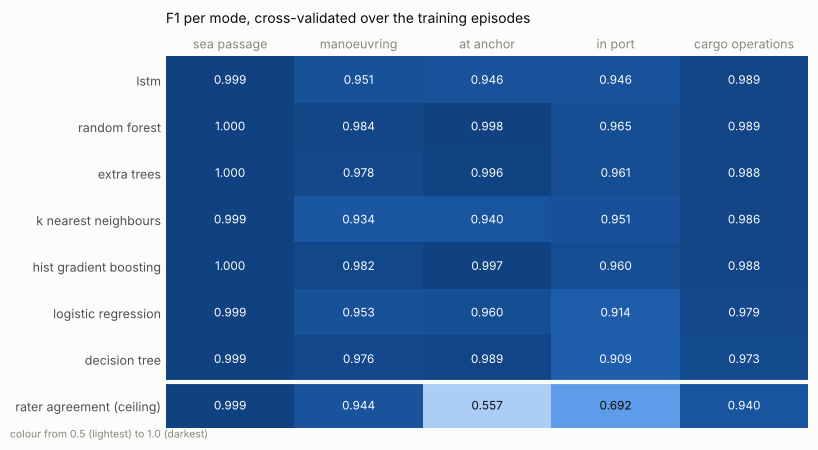

In [20]:
cv_f1 = pd.DataFrame({name: f1_score(y_train, p, labels=MODES, average=None, zero_division=0)
                      for name, p in cv_pred.items()}, index=MODES).T.loc[test_scores.index]
cv_f1.loc["rater agreement (ceiling)"] = rater_f1
f1_heatmap(cv_f1, "F1 per mode, cross-validated over the training episodes")

## 8. Why the split has to be by episode

The same Random Forest, cross-validated twice on the same training rows: once with the rows
shuffled into folds (what `train_test_split` or plain `KFold(shuffle=True)` does), once with
episodes kept whole. The gap between the two is the leak: with shuffled rows, every test
minute has its neighbours one minute either side in the training set.

In [21]:
def row_cv(estimator, splits):
    # Plain cross-validation on the rows of `train`, for any list of (fit rows, score rows).
    pooled = np.empty(len(y_train), dtype=object)
    per_fold = []
    for tr, te in splits:
        m = clone(estimator).fit(X_train.iloc[tr], y_train.iloc[tr])
        pooled[te] = m.predict(X_train.iloc[te])
        per_fold.append(macro_f1_present(y_train.iloc[te], pooled[te]))
    return pooled, np.array(per_fold)


demo = ESTIMATORS["random_forest"]
row_folds = list(KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X_train))

leak = {}
for label, splits in [("rows shuffled into folds (leaks)", row_folds),
                      ("episodes kept whole (honest)", folds)]:
    pooled, per_fold = row_cv(demo, splits)
    leak[label] = {"macro_f1_mean": per_fold.mean(), "macro_f1_std": per_fold.std(),
                   **dict(zip(MODES, f1_score(y_train, pooled, labels=MODES, average=None, zero_division=0)))}
pd.DataFrame(leak).T.round(3)

,macro_f1_mean,macro_f1_std,sea_passage,manoeuvring,at_anchor,in_port,cargo_operations
rows shuffled into folds (leaks),0.999,0.000,1.0,0.998,1.000,0.999,1.000
episodes kept whole (honest),0.988,0.008,1.0,0.984,0.998,0.965,0.989


## 9. Side by side

Test is one honest draw; cross-validation is the average over five. A model that is high on
one and low on the other is less trustworthy than one that is steady on both.

In [22]:
compare = test_scores[["macro_f1", "macro_f1_clean", "accuracy", "kappa"]].add_prefix("test_").join(
    cv_scores[["cv_macro_f1_mean", "cv_macro_f1_std", "cv_macro_f1_worst_fold"]])
compare["test_in_port_f1"] = test_f1.loc[compare.index, "in_port"]
compare["test_at_anchor_f1"] = test_f1.loc[compare.index, "at_anchor"]
compare["fit_s"] = test_scores["fit_s"]
compare.round(3)

,test_macro_f1,test_macro_f1_clean,test_accuracy,test_kappa,cv_macro_f1_mean,cv_macro_f1_std,cv_macro_f1_worst_fold,test_in_port_f1,test_at_anchor_f1,fit_s
model,,,,,,,,,,
lstm,0.957,0.961,0.983,0.969,0.968,0.035,0.906,0.855,0.999,80.206
random_forest,0.956,0.961,0.983,0.969,0.988,0.008,0.976,0.849,0.998,26.911
extra_trees,0.954,0.958,0.982,0.968,0.985,0.008,0.972,0.844,0.995,5.006
k_nearest_neighbours,0.944,0.949,0.978,0.959,0.962,0.034,0.905,0.806,0.994,0.446
hist_gradient_boosting,0.937,0.944,0.980,0.963,0.986,0.007,0.974,0.784,0.979,20.482
logistic_regression,0.927,0.933,0.976,0.955,0.960,0.017,0.930,0.800,0.916,1.774
decision_tree,0.863,0.868,0.958,0.925,0.965,0.024,0.930,0.817,0.608,2.074


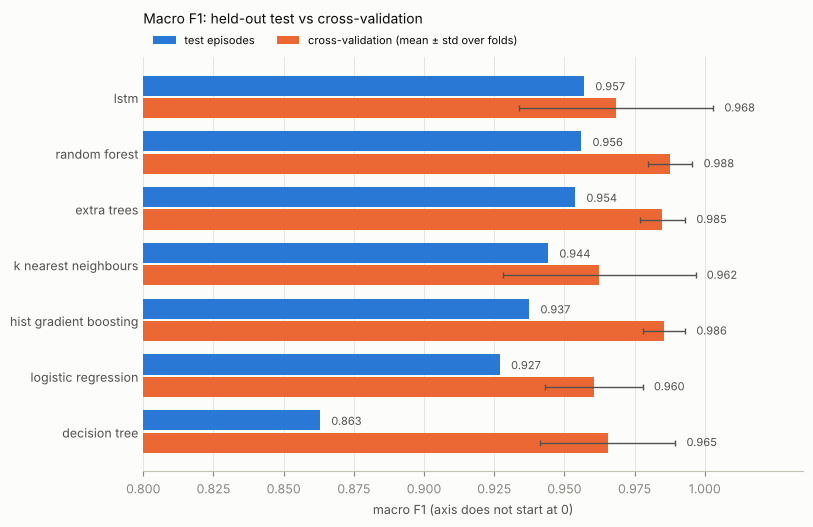

In [23]:
order = compare.sort_values("test_macro_f1").index
y = np.arange(len(order))
h = 0.38
fig, ax = plt.subplots(figsize=(8.2, 0.62 * len(order) + 1.0))
ax.barh(y + h / 2 + 0.01, compare.loc[order, "test_macro_f1"], height=h - 0.02, color=BLUE, label="test episodes")
ax.barh(y - h / 2 - 0.01, compare.loc[order, "cv_macro_f1_mean"], height=h - 0.02, color=ORANGE,
        xerr=compare.loc[order, "cv_macro_f1_std"], error_kw={"ecolor": INK_2, "elinewidth": 1, "capsize": 2},
        label="cross-validation (mean ± std over folds)")
for yi, name in zip(y, order):
    ax.text(compare.loc[name, "test_macro_f1"] + 0.004, yi + h / 2, f"{compare.loc[name, 'test_macro_f1']:.3f}",
            va="center", fontsize=8, color=INK_2)
    ax.text(compare.loc[name, "cv_macro_f1_mean"] + compare.loc[name, "cv_macro_f1_std"] + 0.004, yi - h / 2,
            f"{compare.loc[name, 'cv_macro_f1_mean']:.3f}", va="center", fontsize=8, color=INK_2)
lo = max(0.0, np.floor((compare[["test_macro_f1", "cv_macro_f1_mean"]].min().min() - 0.05) * 20) / 20)
ax.set_xlim(lo, 1.035)
ax.set_xticks(np.arange(lo, 1.0001, 0.025))
ax.set_yticks(y, [n.replace("_", " ") for n in order])
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", linewidth=0.6)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.set_xlabel("macro F1 (axis does not start at 0)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=8)
ax.set_title("Macro F1: held-out test vs cross-validation", loc="left", fontsize=10, pad=24)
plt.tight_layout()
plt.show()

## 10. What Random Forest relies on

**Permutation importance**: shuffle one input across the test rows, so it no longer lines up
with anything, and see how far macro F1 drops. A big drop means the model leans on it.

Many features are near-twins (`sog_mean_15` and `sog_mean_60`, power and fuel). Shuffle one
and the model falls back on its twin, so each looks unimportant on its own. Shuffling a whole
**family** at once answers the more useful question: which kind of signal carries the decision.
This is also where to check the readme's warning: features that describe *what the ship is
doing* should matter, features that only describe *which ship* should not.

random_forest: macro F1 0.956 on 20,000 test rows before shuffling


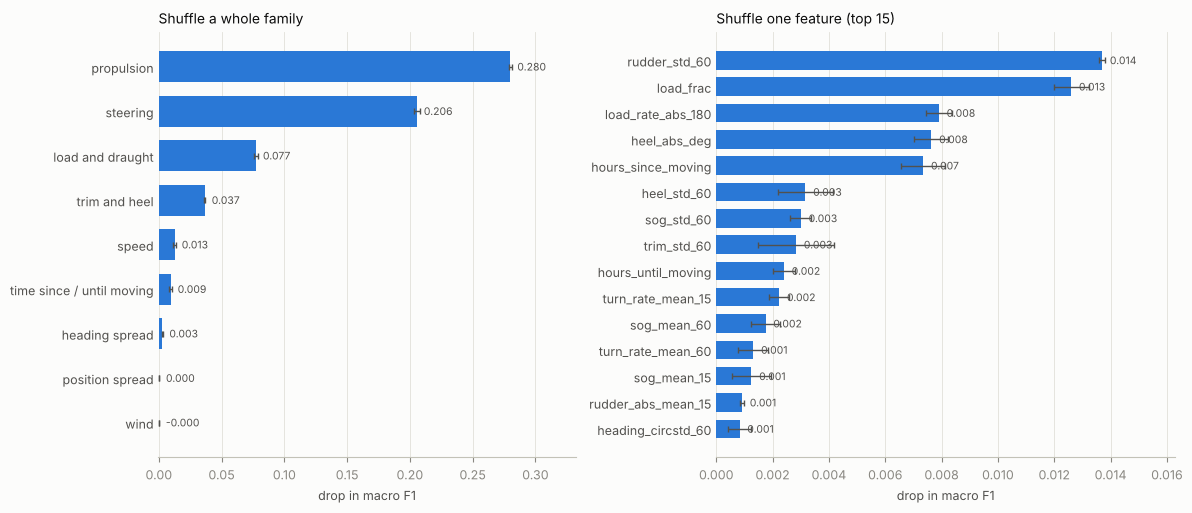

In [24]:
IMPORTANCE_MODEL = "random_forest"
FAMILIES = {
    "speed": ["sog_kn", "stw_frac", "stw_minus_sog_kn", "sog_mean_15", "sog_std_15", "sog_mean_60",
              "sog_std_60", "stw_minus_sog_mean_60"],
    "propulsion": ["power_frac", "rpm_frac", "fuel_frac", "power_frac_mean_15", "power_frac_std_15",
                   "power_frac_mean_60", "power_frac_std_60"],
    "steering": ["rudder_abs_deg", "rudder_abs_mean_15", "rudder_std_15", "rudder_abs_mean_60",
                 "rudder_std_60", "turn_rate_mean_15", "turn_rate_mean_60"],
    "heading spread": ["heading_circstd_60", "heading_circstd_180"],
    "position spread": ["pos_spread_60_shiplengths", "pos_spread_180_shiplengths"],
    "load and draught": ["load_frac", "load_rate_abs_60", "load_rate_abs_180"],
    "trim and heel": ["trim_std_60", "trim_std_180", "heel_std_60", "heel_std_180", "heel_abs_deg"],
    "wind": ["wind_rel_kn", "wind_rel_cos", "wind_rel_cos_mean_60"],
    "time since / until moving": ["hours_since_moving", "hours_until_moving"],
}
assert sorted(sum(FAMILIES.values(), [])) == sorted(FEATURES), "every feature in exactly one family"

assert IMPORTANCE_MODEL != "lstm", "this shuffles single rows; for the LSTM shuffle within sequences instead"
model = fitted[IMPORTANCE_MODEL]
sample = test.sample(n=min(20_000, len(test)), random_state=RANDOM_STATE)
Xs, ys = sample[FEATURES], sample["mode"]
base = macro_f1_present(ys, model.predict(Xs))
rng = np.random.default_rng(RANDOM_STATE)


def drop_when_shuffled(cols, repeats=3):
    drops = []
    for _ in range(repeats):
        Xp = Xs.copy()
        Xp[cols] = Xs[cols].to_numpy()[rng.permutation(len(Xs))]   # same shuffle for the whole family
        drops.append(base - macro_f1_present(ys, model.predict(Xp)))
    return np.mean(drops), np.std(drops)


fam = pd.DataFrame([(f, *drop_when_shuffled(cols)) for f, cols in FAMILIES.items()],
                   columns=["family", "f1_drop", "std"]).set_index("family").sort_values("f1_drop")
one = pd.DataFrame([(c, *drop_when_shuffled([c])) for c in FEATURES],
                   columns=["feature", "f1_drop", "std"]).set_index("feature").sort_values("f1_drop")
print(f"{IMPORTANCE_MODEL}: macro F1 {base:.3f} on {len(sample):,} test rows before shuffling")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1, 1.1]})
for ax, t, title in [(axes[0], fam, "Shuffle a whole family"),
                     (axes[1], one.tail(15), "Shuffle one feature (top 15)")]:
    ax.barh(range(len(t)), t["f1_drop"], xerr=t["std"], height=0.7, color=BLUE,
            error_kw={"ecolor": INK_2, "elinewidth": 1, "capsize": 2})
    for i, v in enumerate(t["f1_drop"]):
        ax.text(max(v, 0) + t["f1_drop"].max() * 0.02, i, f"{v:.3f}", va="center", fontsize=7.5, color=INK_2)
    ax.set_xlim(min(0, (t["f1_drop"] - t["std"]).min() * 1.2), (t["f1_drop"] + t["std"]).max() * 1.18)
    ax.set_yticks(range(len(t)), t.index)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.set_xlabel("drop in macro F1")
    ax.set_title(title, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

### What the default run showed (25 Oct 2026, time split)

- **LSTM and Random Forest tie on the unseen test episodes**: macro F1 0.957 and 0.956,
  in_port 0.855 and 0.849. Both beat HGB (0.937, in_port 0.784). Extra Trees is close behind
  (0.954) and trains about 5 times faster than the forest.
- **In cross-validation the LSTM is the least steady model**: 0.968 ± 0.035 with a worst fold
  of 0.906 (fold 2, which holds the anchorage at the very start of the data), against
  0.988 ± 0.008 for Random Forest. With 13 training episodes the LSTM sees few examples of
  each kind of sequence, and the rolling-window features already give the row models most of
  the before-and-after context. One good test score is not enough to prefer it; Random Forest
  is the safer choice, the LSTM the one to watch if more labelled episodes arrive.
- **Every model scores lower on test than in cross-validation**, from 0.01 (LSTM) to 0.10
  (decision tree). The test episodes are later in time and labelled by labeller A alone; the
  training episodes mix A and B.
- **The leak is real**: the same forest scores 0.999 with shuffled rows and 0.988 with whole
  episodes; in_port drops from 0.999 to 0.965.
- **One tree is not enough**: the depth-8 tree scores 0.965 in cross-validation but 0.863 on
  test, with at_anchor at 0.608.
- **The remaining in_port errors look like a labelling question.** Random Forest calls 1,000
  labelled cargo minutes in_port. 971 of them are in two port calls (wendover-trader-09 and -10)
  and 740 are more than an hour from any label edge. In those minutes the load rate is under a
  tenth of normal cargo work (0.0013 vs 0.0167 of a full load per hour) and trim and heel are
  steady: nothing was going in or out. A pause in cargo work that the labeller kept calling
  cargo_operations? The LSTM's in_port score (0.855) says it does not get past this either.
  Whether a pause counts as cargo operations is a question for the mode scheme, not something
  a better model can fix.
- **The wind dropout hint is not what the forest relies on**: shuffling the wind family costs
  nothing. Propulsion and steering carry the decision, then load and draught.

## 11. Optional: tune Random Forest with grouped cross-validation

Set `RUN_TUNING = True` at the top. A random search over a few settings, each scored with the
same episode folds as step 7, never with the test set. Only the winner is then scored on test,
once. Takes several minutes (`n_iter × N_FOLDS` forests).

In [25]:
if RUN_TUNING:
    search = RandomizedSearchCV(
        make_pipeline(*prep(False), RandomForestClassifier(n_jobs=N_JOBS, random_state=RANDOM_STATE)),
        param_distributions={
            "randomforestclassifier__n_estimators": [200, 400],
            "randomforestclassifier__max_features": ["sqrt", 0.3, 0.5],
            "randomforestclassifier__min_samples_leaf": [1, 3, 10, 30],
            "randomforestclassifier__max_depth": [None, 25, 12],
            "randomforestclassifier__class_weight": ["balanced_subsample", None],
        },
        n_iter=10, scoring=SCORER, cv=folds, random_state=RANDOM_STATE, refit=True, verbose=1)
    search.fit(X_train, y_train)

    res = pd.DataFrame(search.cv_results_)
    cols = ["mean_test_score", "std_test_score"] + [c for c in res.columns if c.startswith("param_")]
    display(res.sort_values("rank_test_score")[cols].rename(
        columns=lambda c: c.replace("param_randomforestclassifier__", "")).round(3).head(10))
    tuned_pred = search.best_estimator_.predict(X_test)
    print(f"tuned on CV: {search.best_score_:.3f}   on test, once: {macro_f1_present(y_test, tuned_pred):.3f}   "
          f"(untuned RF on test: {test_scores.loc['random_forest', 'macro_f1']:.3f})")
else:
    print("RUN_TUNING is False, skipped")

RUN_TUNING is False, skipped


## 12. Using another model in the dataset notebook

`show_range` and the block tables in `operating_mode_dataset(2).ipynb` work with any
classifier that has `predict_proba` and `classes_`, pipelines included. To plot Random
Forest's blocks instead of HGB's, replace the `clf = ...` line in its section 7 with:

```python
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

clf = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                    RandomForestClassifier(n_estimators=300, min_samples_leaf=3, max_features="sqrt",
                                           class_weight="balanced_subsample", n_jobs=-1, random_state=0))
```

That notebook does not apply `clean_features`; the difference is a few hundred clipped wind
values and the start-of-data anchorage, so the blocks will look the same.

Things worth trying next here:
- `USE_MISSING_FLAGS = False`: does manoeuvring hold up without the wind-dropout hint? That
  is the safer bet for the supplier-Y ships.
- `SPLIT = "vessel"`: train on one ship, test on the other.
- LSTM settings: a longer `seq_len` (480 or 720 minutes) gives it a whole port call of
  context; compare `epochs` values with cross-validation, not on test.

`show_range` there feeds the classifier one feature table per time range, which is all the
row models need. The LSTM additionally needs the `vessel`, `timestamp` and `near_boundary`
columns, so it does not drop into that notebook as-is.